In [3]:
import pandas as pd

df = pd.read_csv("../data/processed/emails.csv")

df["subject"] = df["subject"].fillna("")
df["body"] = df["body"].fillna("")

df["text"] = df["subject"] + " " + df["body"]

In [4]:
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [5]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [6]:
def preprocess(text):

    text = str(text)

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    text = text.translate(str.maketrans("", "", string.punctuation))

    words = word_tokenize(text)

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word.isalpha() and word not in stop_words
    ]

    return " ".join(words)

In [7]:
df["clean_text"] = df["text"].apply(preprocess)

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["clean_text"])

y = df["label"]

In [9]:
print(X.shape)
print(y.shape)

(5996, 5000)
(5996,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (4796, 5000)
Testing set: (1200, 5000)


In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [12]:
y_pred = model.predict(X_test)

In [13]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9783333333333334

Classification Report
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1001
           1       1.00      0.87      0.93       199

    accuracy                           0.98      1200
   macro avg       0.99      0.93      0.96      1200
weighted avg       0.98      0.98      0.98      1200


Confusion Matrix
[[1001    0]
 [  26  173]]


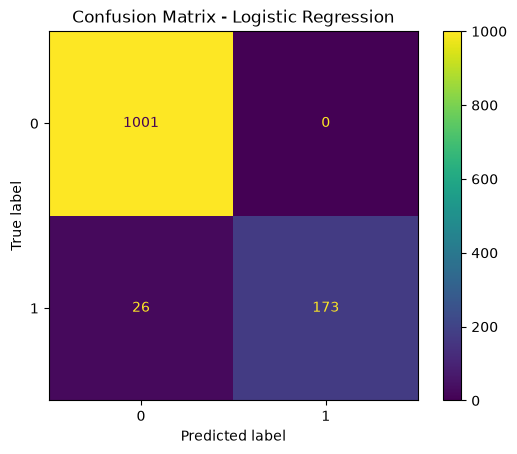

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [15]:
import joblib

joblib.dump(model, "../models/logistic_model.pkl")

joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [ ]:
# ======================================
# XGBoost Classifier
# ======================================

In [16]:
from xgboost import XGBClassifier

In [17]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

print("✅ XGBoost trained successfully!")

✅ XGBoost trained successfully!


In [18]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

xgb_predictions = xgb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, xgb_predictions))

print("\nClassification Report\n")
print(classification_report(y_test, xgb_predictions))

print("\nConfusion Matrix\n")
print(confusion_matrix(y_test, xgb_predictions))

Accuracy: 0.9975

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1001
           1       0.99      1.00      0.99       199

    accuracy                           1.00      1200
   macro avg       0.99      1.00      1.00      1200
weighted avg       1.00      1.00      1.00      1200


Confusion Matrix

[[998   3]
 [  0 199]]


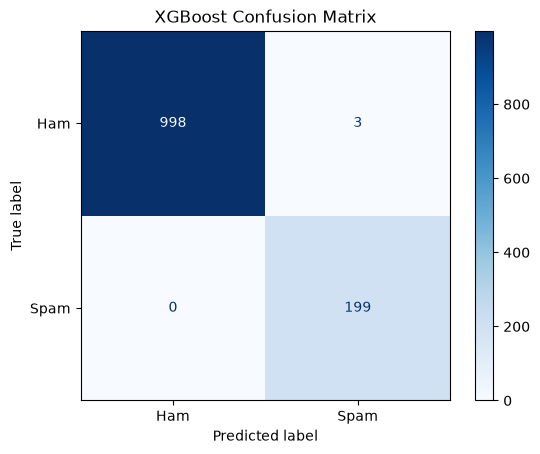

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_predictions,
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [20]:
import joblib

joblib.dump(xgb_model, "../models/xgboost.pkl")

print("✅ XGBoost model saved successfully!")

✅ XGBoost model saved successfully!


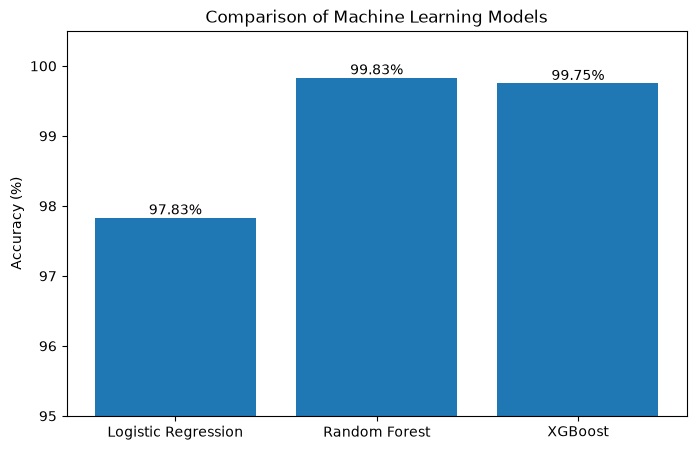

In [21]:
import matplotlib.pyplot as plt

models = ["Logistic Regression", "Random Forest", "XGBoost"]
accuracy = [97.83, 99.83, 99.75]

plt.figure(figsize=(8,5))
plt.bar(models, accuracy)

plt.ylabel("Accuracy (%)")
plt.title("Comparison of Machine Learning Models")

for i, value in enumerate(accuracy):
    plt.text(i, value + 0.05, f"{value:.2f}%", ha="center")

plt.ylim(95, 100.5)

plt.show()

# ======================================
# Hyperparameter Tuning - Random Forest
# ======================================

In [22]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [23]:
rf = RandomForestClassifier(random_state=42)

In [24]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}

In [25]:
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20, ...], 'max_features': ['sqrt'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_example

In [26]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
0.9941616701425096


In [27]:
best_rf = grid_search.best_estimator_

predictions = best_rf.predict(X_test)

In [28]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))
print(confusion_matrix(y_test, predictions))

Accuracy: 0.9983333333333333
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1001
           1       0.99      1.00      0.99       199

    accuracy                           1.00      1200
   macro avg       1.00      1.00      1.00      1200
weighted avg       1.00      1.00      1.00      1200

[[999   2]
 [  0 199]]


In [29]:
import joblib

joblib.dump(best_rf, "../models/random_forest_tuned.pkl")

['../models/random_forest_tuned.pkl']